# 10 · Text classification with classic ML

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/10_text_classification_classic_ml.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 10 of 12*

Everything so far turned text into numbers. Now we put those numbers to work: **text classification**
means learning, from labelled examples, a function that assigns a category to a new document — spam or
ham, sport or space, positive or negative. In this notebook we train the three classic workhorses of text
classification — **Multinomial Naive Bayes**, **Logistic Regression** and the **Linear Support Vector
Machine** — on TF-IDF features of the 4-category newsgroups data, compare them across the representations
built earlier in the course (Bag-of-Words, TF-IDF, n-grams, averaged word2vec), and look inside the models
to see *which words* drive their decisions.

### Learning objectives
By the end of this notebook you will be able to:
1. Set up a supervised text-classification experiment with a proper train/test split.
2. Explain how Multinomial Naive Bayes, Logistic Regression and a Linear SVM make predictions from word features.
3. Train and compare the three models with scikit-learn on TF-IDF features.
4. Compare feature representations (BoW, TF-IDF, word + bigram TF-IDF, averaged word2vec) on the same task.
5. Read a confusion matrix, inspect the most informative words per class, and look at misclassified documents.

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn", "gensim>=4.3"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
import time
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from gensim.models import Word2Vec

## 1 · The task and the split
The newsgroups data comes with an official **train / test split** (by date): we learn only from the
training posts and report performance only on the test posts, which the model never sees during training.
We clean every post once with the course's `preprocess()` helper (notebook 02) and join the tokens back
into a string so that scikit-learn's vectorizers can read it.

In [3]:
train = nlp_course.load_newsgroups("train")
test = nlp_course.load_newsgroups("test")
t0 = time.time()
for df in (train, test):
    df["clean"] = df["text"].map(lambda s: " ".join(nlp_course.preprocess(s)))
print(f"Preprocessed {len(train) + len(test):,} posts in {time.time() - t0:.1f} s")
print("train:", len(train), "  test:", len(test))
both = pd.concat([train, test], ignore_index=True)
print(pd.crosstab(both["category"], both["subset"]))

Preprocessed 3,729 posts in 4.5 s
train: 2239   test: 1490
subset              test  train
category                       
comp.graphics        389    584
rec.sport.baseball   397    597
sci.space            394    593
talk.politics.misc   310    465


In [4]:
y_train, y_test = train["category"].to_numpy(), test["category"].to_numpy()
classes = sorted(train["category"].unique())
print(classes)
print("\nA cleaned training post:\n", train.loc[0, "clean"][:300])

['comp.graphics', 'rec.sport.baseball', 'sci.space', 'talk.politics.misc']

A cleaned training post:
 yes long star trek einstein fact vulcan planet inside mercury hypothesize explain perturbation mercury orbit could explain know planet einstein theory relativity explain mercury motion analysis mercury motion show planet inside orbit


## 2 · Features: TF-IDF, fitted on the training set only
The vectorizer's vocabulary and IDF weights are **learned from the training posts only** and then
applied unchanged to the test posts (`fit_transform` on train, `transform` on test). Fitting on the test
data would leak information — notebook 11 shows why this matters. We use `sublinear_tf=True`
(TF = 1 + log count, notebook 04) and drop words seen in fewer than 2 training posts.

In [5]:
tfidf = TfidfVectorizer(min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(train["clean"])
X_test = tfidf.transform(test["clean"])
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print(f"Non-zero entries in X_train: {X_train.nnz:,} ({X_train.nnz / np.prod(X_train.shape):.2%} of the matrix)")

X_train: (2239, 8998)  X_test: (1490, 8998)
Non-zero entries in X_train: 126,546 (0.63% of the matrix)


## 3 · Multinomial Naive Bayes
Naive Bayes applies Bayes' rule with the *naive* assumption that words occur independently given the class:

$$\hat{y} = \arg\max_c \; \log P(c) + \sum_{w} x_w \log P(w \mid c)$$

$P(w \mid c)$ is estimated from how often word $w$ appears in training documents of class $c$, with
**additive (Laplace/Lidstone) smoothing** `alpha` so that an unseen word does not give probability zero.
Training is a single pass of counting — it is extremely fast and a strong baseline for text.

In [6]:
nb = MultinomialNB(alpha=0.1)
t0 = time.time()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)
print(f"Naive Bayes  fit time {time.time() - t0:.3f} s   test accuracy {accuracy_score(y_test, pred_nb):.3f}")

Naive Bayes  fit time 0.005 s   test accuracy 0.892


Under the hood the model is just a table of log-probabilities: one row per class, one column per word.
The words with the highest $P(w \mid c)$ for each class are its most typical words:

In [7]:
vocab = tfidf.get_feature_names_out()
for c, row in zip(nb.classes_, nb.feature_log_prob_):
    print(f"{c:>20}: {', '.join(vocab[np.argsort(-row)[:8]])}")

       comp.graphics: file, graphic, thank, use, image, program, know, look
  rec.sport.baseball: game, team, year, player, run, baseball, pitch, think
           sci.space: space, would, get, orbit, launch, think, one, nasa
  talk.politics.misc: people, say, would, make, government, state, get, one


Typical is not the same as *distinctive*: general words such as "would", "think" or "one" are frequent
in several classes. What decides the prediction is how $P(w \mid c)$ *differs* between classes — section 8
shows the most distinctive words of a discriminative model.

## 4 · Logistic Regression
Logistic Regression learns one **weight per word per class** and turns the weighted sum into class
probabilities with the softmax function:

$$P(c \mid \mathbf{x}) = \frac{\exp(\mathbf{w}_c \cdot \mathbf{x} + b_c)}{\sum_{k} \exp(\mathbf{w}_k \cdot \mathbf{x} + b_k)}$$

Unlike Naive Bayes it does not assume independent words: the weights are fitted jointly by minimising the
log-loss, with L2 regularisation controlled by `C` (larger `C` = weaker regularisation).

In [8]:
lr = LogisticRegression(C=10, max_iter=2000)
t0 = time.time()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
print(f"Logistic Regression  fit time {time.time() - t0:.3f} s   test accuracy {accuracy_score(y_test, pred_lr):.3f}")
print("\nPredicted probabilities for the first test post:")
print(pd.Series(lr.predict_proba(X_test[:1])[0], index=lr.classes_).round(3), "\n  true label:", y_test[0])

Logistic Regression  fit time 5.301 s   test accuracy 0.863

Predicted probabilities for the first test post:
comp.graphics         0.982
rec.sport.baseball    0.002
sci.space             0.015
talk.politics.misc    0.001
dtype: float64 
  true label: comp.graphics


## 5 · Linear Support Vector Machine
A linear SVM also learns one weight vector per class (one-vs-rest), but instead of probabilities it looks
for the hyperplane with the **largest margin** between classes (hinge loss). It outputs scores, not
probabilities. Linear SVMs were the state of the art for text classification for over a decade, because
text features are high-dimensional and sparse — exactly where linear separators work well.

In [9]:
svm = LinearSVC(C=1.0)
t0 = time.time()
svm.fit(X_train, y_train)
pred_svm = svm.predict(X_test)
print(f"Linear SVM  fit time {time.time() - t0:.3f} s   test accuracy {accuracy_score(y_test, pred_svm):.3f}")
print("Decision scores for the first test post:",
      {c: round(float(v), 2) for c, v in zip(svm.classes_, svm.decision_function(X_test[:1])[0])})

Linear SVM  fit time 0.045 s   test accuracy 0.859
Decision scores for the first test post: {'comp.graphics': 1.08, 'rec.sport.baseball': -1.34, 'sci.space': -0.71, 'talk.politics.misc': -1.59}


## 6 · Which representation and which model?
We now train all three models on four representations built earlier in the course:

| Representation | From notebook | Features |
|---|---|---|
| Bag-of-Words counts | 03 | `CountVectorizer(min_df=2)` |
| TF-IDF | 04 | `TfidfVectorizer(min_df=2, sublinear_tf=True)` |
| TF-IDF, words + bigrams | 05 | same, `ngram_range=(1, 2)` |
| Averaged word2vec | 08 | mean of 100-d skip-gram vectors trained on the training posts only |

Multinomial Naive Bayes needs non-negative features, so it is not applied to the word2vec averages
(which can be negative).

In [10]:
tokens_train = [s.split() for s in train["clean"]]
tokens_test = [s.split() for s in test["clean"]]
w2v = Word2Vec(tokens_train, vector_size=100, window=5, min_count=2, sg=1, epochs=20, seed=0, workers=1)

def average_vectors(token_lists, model):
    out = np.zeros((len(token_lists), model.vector_size))
    for i, toks in enumerate(token_lists):
        vecs = [model.wv[t] for t in toks if t in model.wv]
        if vecs:
            out[i] = np.mean(vecs, axis=0)
    return out

reps = {
    "BoW counts": CountVectorizer(min_df=2),
    "TF-IDF": TfidfVectorizer(min_df=2, sublinear_tf=True),
    "TF-IDF 1-2 grams": TfidfVectorizer(min_df=2, sublinear_tf=True, ngram_range=(1, 2)),
}
features = {}
for name, vec in reps.items():
    features[name] = (vec.fit_transform(train["clean"]), vec.transform(test["clean"]))
features["avg word2vec"] = (average_vectors(tokens_train, w2v), average_vectors(tokens_test, w2v))

models = {
    "Naive Bayes": lambda: MultinomialNB(alpha=0.1),
    "Logistic Regression": lambda: LogisticRegression(C=10, max_iter=3000),
    "Linear SVM": lambda: LinearSVC(C=1.0),
}
rows = []
for rep, (Xtr, Xte) in features.items():
    for mname, make in models.items():
        if mname == "Naive Bayes" and rep == "avg word2vec":
            continue
        pred = make().fit(Xtr, y_train).predict(Xte)
        rows.append({"representation": rep, "model": mname, "n_features": Xtr.shape[1],
                     "accuracy": accuracy_score(y_test, pred), "macro_F1": f1_score(y_test, pred, average="macro")})
results = pd.DataFrame(rows)
print(results.pivot(index="representation", columns="model", values="accuracy").round(3)
      .loc[list(features)])
print()
print(results.drop_duplicates("representation").set_index("representation")["n_features"])

model             Linear SVM  Logistic Regression  Naive Bayes
representation                                                
BoW counts             0.801                0.822        0.878
TF-IDF                 0.859                0.863        0.892
TF-IDF 1-2 grams       0.865                0.862        0.887
avg word2vec           0.861                0.860          NaN

representation
BoW counts           8998
TF-IDF               8998
TF-IDF 1-2 grams    27962
avg word2vec          100
Name: n_features, dtype: int64


In [11]:
best = results.sort_values("accuracy", ascending=False).iloc[0]
print(f"Best combination: {best['model']} on {best['representation']} — accuracy {best['accuracy']:.3f}, macro-F1 {best['macro_F1']:.3f}")
for rep in features:
    sub = results[results["representation"] == rep]
    print(f"{rep:>17}: best {sub['accuracy'].max():.3f} ({sub.loc[sub['accuracy'].idxmax(), 'model']})")

Best combination: Naive Bayes on TF-IDF — accuracy 0.892, macro-F1 0.890
       BoW counts: best 0.878 (Naive Bayes)
           TF-IDF: best 0.892 (Naive Bayes)
 TF-IDF 1-2 grams: best 0.887 (Naive Bayes)
     avg word2vec: best 0.861 (Linear SVM)


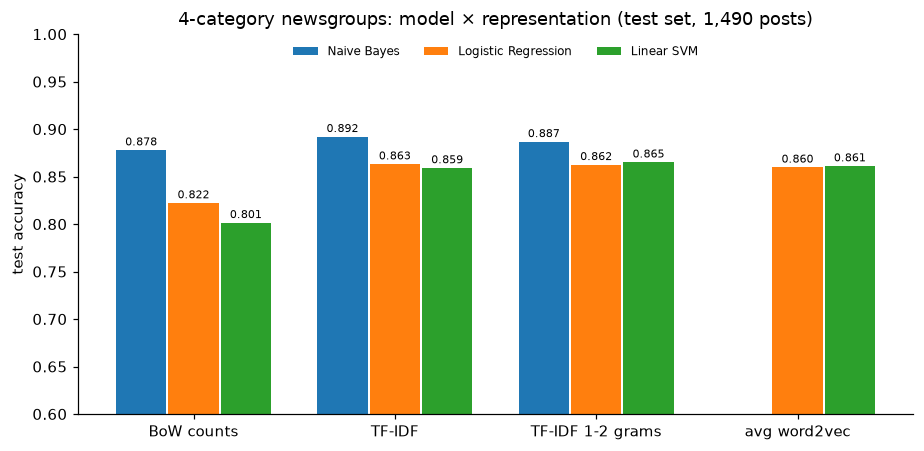

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
piv = results.pivot(index="representation", columns="model", values="accuracy").loc[list(features)]
piv = piv[["Naive Bayes", "Logistic Regression", "Linear SVM"]]
xs = np.arange(len(piv))
for k, m in enumerate(piv.columns):
    vals = piv[m].to_numpy()
    bars = ax.bar(xs + (k - 1) * 0.26, np.nan_to_num(vals), width=0.25, label=m)
    for x, v in zip(xs + (k - 1) * 0.26, vals):
        if not np.isnan(v):
            ax.text(x, v + 0.005, f"{v:.3f}", ha="center", fontsize=7.5)
ax.set_xticks(xs, piv.index)
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("test accuracy")
ax.set_title("4-category newsgroups: model × representation (test set, 1,490 posts)")
ax.legend(loc="upper center", ncol=3, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(DOCS / "10_model_comparison.png", bbox_inches="tight")
plt.show()

What the table and the chart show on this dataset:
- **TF-IDF beats raw counts** for every model: down-weighting common words (notebook 04) helps classification too.
- **Naive Bayes is the best model here**, despite its "naive" assumption — on small training sets
  (2,239 posts) its strong assumptions act as regularisation. Logistic Regression and the Linear SVM are
  close behind; with much more training data the discriminative models usually catch up and pass it.
- **Adding bigrams** multiplies the number of features by about three but changes accuracy by less than one
  percentage point (slightly up for the SVM, slightly down for the other two).
- **Averaged word2vec vectors** — only 100 dense features learned from this small corpus — do surprisingly
  well: Logistic Regression and the SVM on them score about the same as on 8,998 TF-IDF features, and better
  than on raw counts. But they cannot be used with Multinomial Naive Bayes, so they do not reach the best
  TF-IDF result: averaging blurs *which* rare, topical words are present.

## 7 · The confusion matrix
Accuracy is one number; the **confusion matrix** shows *which* classes get confused. Row = true class,
column = predicted class. We use Naive Bayes on TF-IDF.

                    comp.graphics  rec.sport.baseball  sci.space  \
comp.graphics                 358                  12         14   
rec.sport.baseball             10                 369          4   
sci.space                      16                  22        336   
talk.politics.misc              4                  15         25   

                    talk.politics.misc  
comp.graphics                        5  
rec.sport.baseball                  14  
sci.space                           20  
talk.politics.misc                 266  


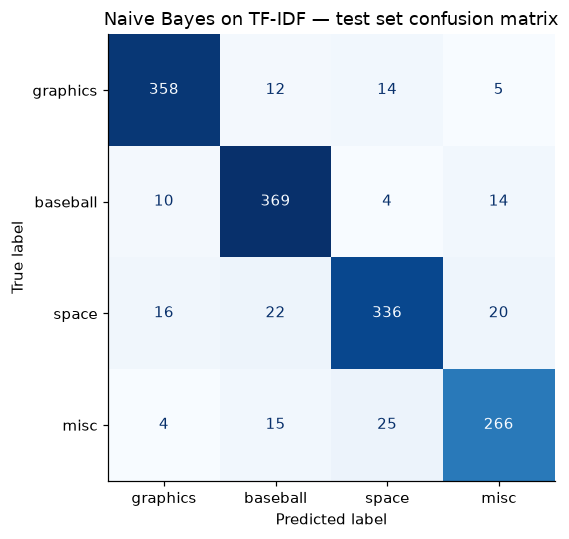

In [13]:
cm = confusion_matrix(y_test, pred_nb, labels=classes)
print(pd.DataFrame(cm, index=classes, columns=classes))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=[c.split(".")[-1] for c in classes]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Naive Bayes on TF-IDF — test set confusion matrix")
fig.tight_layout()
fig.savefig(DOCS / "10_confusion_matrix.png", bbox_inches="tight")
plt.show()

In [14]:
off = cm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"Most frequent error: {classes[i]} predicted as {classes[j]} ({off[i, j]} posts)")
print()
print(classification_report(y_test, pred_nb, digits=3))

Most frequent error: talk.politics.misc predicted as sci.space (25 posts)

                    precision    recall  f1-score   support

     comp.graphics      0.923     0.920     0.921       389
rec.sport.baseball      0.883     0.929     0.906       397
         sci.space      0.887     0.853     0.869       394
talk.politics.misc      0.872     0.858     0.865       310

          accuracy                          0.892      1490
         macro avg      0.891     0.890     0.890      1490
      weighted avg      0.892     0.892     0.892      1490



## 8 · Looking inside the model: the most informative words
A linear model is interpretable: each class has one weight per word. The words with the largest positive
Logistic Regression weights push a post toward that class.

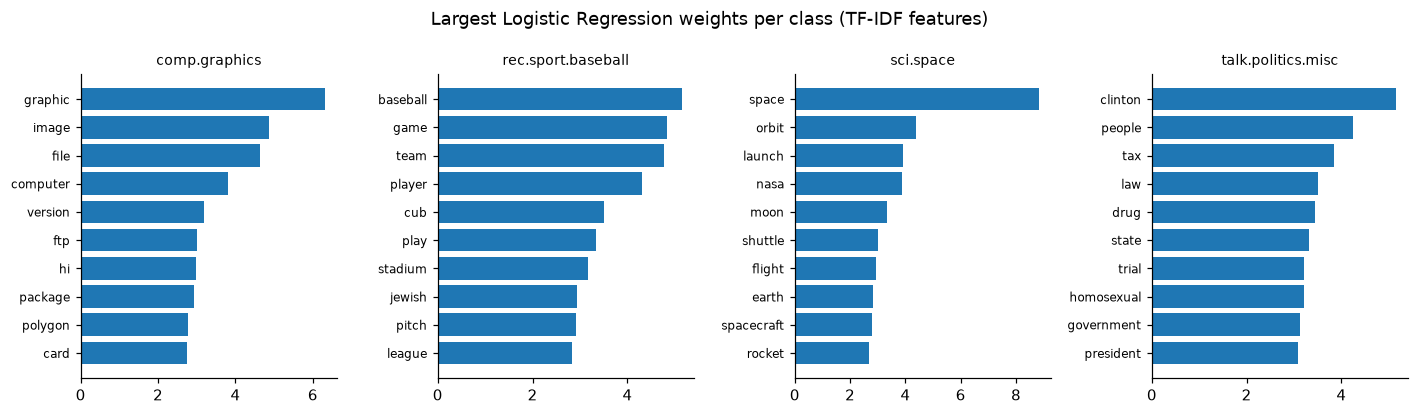

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
for ax, c, w in zip(axes, lr.classes_, lr.coef_):
    top = np.argsort(-w)[:10][::-1]
    ax.barh(vocab[top], w[top], color="tab:blue")
    ax.set_title(c, fontsize=9)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Largest Logistic Regression weights per class (TF-IDF features)")
fig.tight_layout()
fig.savefig(DOCS / "10_top_features.png", bbox_inches="tight")
plt.show()

These words are the model's evidence. Most are clearly topical (*graphic, baseball, orbit, tax*). Others are
artefacts of *this* dataset: *jewish* ranks among the top baseball words because 20 training posts in
rec.sport.baseball discuss Jewish baseball players (only 5 politics posts use the word), and *clinton* tops
politics because the posts date from 1993. A model learns whatever separates the classes in its training
data, including shortcuts that would not generalise to other years or sources.

## 9 · Where does the model go wrong?

In [16]:
wrong = np.where(pred_nb != y_test)[0]
print(f"{len(wrong)} of {len(y_test)} test posts misclassified by Naive Bayes\n")
n_empty = int((test["clean"].str.len() == 0).sum())
print(f"Test posts that are empty after preprocessing: {n_empty} "
      f"({(test.loc[wrong, 'clean'].str.len() == 0).sum()} of them misclassified)\n")
for k in wrong[:3]:
    print(f"true: {y_test[k]:<20} predicted: {pred_nb[k]}")
    print("   ", " ".join(test.loc[k, "text"].split())[:220] or "(empty post)", "\n")

161 of 1490 test posts misclassified by Naive Bayes

Test posts that are empty after preprocessing: 49 (30 of them misclassified)

true: sci.space            predicted: rec.sport.baseball
    (empty post) 

true: sci.space            predicted: comp.graphics
    Sorry, I've lost track of who asked the question originally (our news server at GSFC keeps things around for tremendously short periods of time), but wanted to be certain before I replied. Someone asked about displaying  

true: sci.space            predicted: talk.politics.misc
    1. Please take this out of sci.space. 2. Ayn Rand was not only born in Russia, but educated there. A lot of her philosophy reflects not only a European education but a reaction against certian events in Russia while she  



Some errors are posts with no text at all (the newsgroup headers and quotes were stripped and nothing was
left), some are short posts with few topical words, and some genuinely mix topics — like the post above in
*sci.space* that argues about a political philosopher. No amount of model tuning fixes a document that does
not contain the evidence.

## 10 · Classifying new text
To use the model on fresh text, apply **exactly the same** preprocessing and the **already fitted**
vectorizer, then predict.

In [17]:
new_posts = [
    "The shuttle launch was delayed because of a problem with the booster.",
    "Who will be the starting pitcher for the Yankees tonight?",
    "I need a fast algorithm to render 3D polygons with texture mapping.",
    "The senator voted against the new tax bill in Congress.",
]
X_new = tfidf.transform([" ".join(nlp_course.preprocess(p)) for p in new_posts])
for p, a, b, c in zip(new_posts, nb.predict(X_new), lr.predict(X_new), svm.predict(X_new)):
    print(f"NB={a:<20} LR={b:<20} SVM={c:<20} | {p}")

NB=sci.space            LR=sci.space            SVM=sci.space            | The shuttle launch was delayed because of a problem with the booster.
NB=rec.sport.baseball   LR=rec.sport.baseball   SVM=rec.sport.baseball   | Who will be the starting pitcher for the Yankees tonight?
NB=comp.graphics        LR=comp.graphics        SVM=comp.graphics        | I need a fast algorithm to render 3D polygons with texture mapping.
NB=talk.politics.misc   LR=talk.politics.misc   SVM=talk.politics.misc   | The senator voted against the new tax bill in Congress.


## Exercises
**Exercise 1.** Naive Bayes has one main hyper-parameter, the smoothing `alpha`. Train `MultinomialNB` on
the TF-IDF features with `alpha` in `[0.001, 0.01, 0.1, 0.5, 1.0, 2.0]` and print the test accuracy for each.
(In notebook 11 we will see why choosing `alpha` by test accuracy is itself a pitfall.)

In [18]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Too much smoothing (large alpha) flattens the word probabilities toward uniform and accuracy drops; too little (alpha=0.001) over-trusts rare words and also hurts. A moderate alpha of 0.1 is best on this data.

```python
for a in [0.001, 0.01, 0.1, 0.5, 1.0, 2.0]:
    acc = accuracy_score(y_test, MultinomialNB(alpha=a).fit(X_train, y_train).predict(X_test))
    print(f"alpha={a:<6} accuracy={acc:.3f}")
```
</details>

In [19]:
for a in [0.001, 0.01, 0.1, 0.5, 1.0, 2.0]:
    acc = accuracy_score(y_test, MultinomialNB(alpha=a).fit(X_train, y_train).predict(X_test))
    print(f"alpha={a:<6} accuracy={acc:.3f}")

alpha=0.001  accuracy=0.873
alpha=0.01   accuracy=0.887
alpha=0.1    accuracy=0.892
alpha=0.5    accuracy=0.883
alpha=1.0    accuracy=0.878
alpha=2.0    accuracy=0.868


**Exercise 2.** Train the same three models on the **SMS Spam** data (`nlp_course.load_sms()`), using a
stratified 75/25 split with `random_state=0` and TF-IDF on the raw text. Print accuracy and the F1 score of
the `spam` class for each model.

In [20]:
# your code here

<details>
<summary><b>Show solution</b></summary>

All three models reach high accuracy, but the spam F1 is noticeably lower than the accuracy — because 87% of messages are ham, accuracy flatters every model. That is the starting point of notebook 11.

```python
from sklearn.model_selection import train_test_split
sms = nlp_course.load_sms()
s_tr, s_te = train_test_split(sms, test_size=0.25, stratify=sms["label"], random_state=0)
vec = TfidfVectorizer(sublinear_tf=True)
A, B = vec.fit_transform(s_tr["text"]), vec.transform(s_te["text"])
for mname, make in models.items():
    p = make().fit(A, s_tr["label"]).predict(B)
    print(f"{mname:>20}: accuracy={accuracy_score(s_te['label'], p):.3f}  spam F1={f1_score(s_te['label'], p, pos_label='spam'):.3f}")
```
</details>

In [21]:
from sklearn.model_selection import train_test_split
sms = nlp_course.load_sms()
s_tr, s_te = train_test_split(sms, test_size=0.25, stratify=sms["label"], random_state=0)
vec = TfidfVectorizer(sublinear_tf=True)
A, B = vec.fit_transform(s_tr["text"]), vec.transform(s_te["text"])
for mname, make in models.items():
    p = make().fit(A, s_tr["label"]).predict(B)
    print(f"{mname:>20}: accuracy={accuracy_score(s_te['label'], p):.3f}  spam F1={f1_score(s_te['label'], p, pos_label='spam'):.3f}")

         Naive Bayes: accuracy=0.982  spam F1=0.928
 Logistic Regression: accuracy=0.981  spam F1=0.924
          Linear SVM: accuracy=0.981  spam F1=0.924


**Exercise 3.** Character n-grams are robust to spelling variants and typos. Build a
`TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)` on the **raw**
newsgroup text (not the cleaned text), train a Linear SVM and compare its test accuracy and number of features
with the word-level TF-IDF SVM above.

In [22]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Character n-grams need no tokenizer or preprocessing and use many more features; compare the two printed accuracies to judge whether they pay off here.

```python
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
Ctr = char_vec.fit_transform(train["text"])
Cte = char_vec.transform(test["text"])
acc_char = accuracy_score(y_test, LinearSVC(C=1.0).fit(Ctr, y_train).predict(Cte))
print(f"char 2-5 grams: {Ctr.shape[1]:,} features, SVM accuracy {acc_char:.3f}")
print(f"word TF-IDF   : {X_train.shape[1]:,} features, SVM accuracy {accuracy_score(y_test, pred_svm):.3f}")
```
</details>

In [23]:
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
Ctr = char_vec.fit_transform(train["text"])
Cte = char_vec.transform(test["text"])
acc_char = accuracy_score(y_test, LinearSVC(C=1.0).fit(Ctr, y_train).predict(Cte))
print(f"char 2-5 grams: {Ctr.shape[1]:,} features, SVM accuracy {acc_char:.3f}")
print(f"word TF-IDF   : {X_train.shape[1]:,} features, SVM accuracy {accuracy_score(y_test, pred_svm):.3f}")

char 2-5 grams: 104,327 features, SVM accuracy 0.866
word TF-IDF   : 8,998 features, SVM accuracy 0.859


## Summary
- Text classification = representation + classifier + a train/test split that keeps the test set unseen.
- **Multinomial Naive Bayes** counts words per class; **Logistic Regression** and the **Linear SVM** learn one
  weight per word per class. All three are fast on sparse TF-IDF features.
- On the 4-category newsgroups, TF-IDF beats raw counts, Naive Bayes on TF-IDF is the best combination, bigrams
  add little, and 100-d averaged word2vec vectors match TF-IDF for Logistic Regression and the SVM.
- The confusion matrix shows which classes are confused; the model weights show which words it relies on.
- New text must go through the **same** preprocessing and the **already fitted** vectorizer.

**Next:** [11 · Evaluation and pitfalls](11_evaluation_and_pitfalls.ipynb).